<a href="https://colab.research.google.com/github/oliver4701/qutip-lectures/blob/colab/qutip-lectures%20jrjohansson%20Upated%20%26%20Extended%20in%20CoLab%20Lec-1-Jaynes-Cumming-model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QuTiP lecture: Vacuum Rabi oscillations in the Jaynes-Cummings model

Author: J. R. Johansson (robert@riken.jp), http://dml.riken.jp/~rob/

The latest version of this [IPython notebook](http://ipython.org/ipython-doc/dev/interactive/htmlnotebook.html) lecture is available at [http://github.com/jrjohansson/qutip-lectures](http://github.com/jrjohansson/qutip-lectures).


In [33]:
# setup the matplotlib graphics library and configure it to show
# figures inline in the notebook
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

In [34]:
!pip install qutip
# make qutip available in the rest of the notebook
from qutip import *

# Introduction

The Jaynes-Cumming model is the simplest possible model of quantum mechanical light-matter interaction, describing a single two-level atom interacting with a single electromagnetic cavity mode. The Hamiltonian for this system is (in dipole interaction form)

### $H = \hbar \omega_c a^\dagger a + \frac{1}{2}\hbar\omega_a\sigma_z + \hbar g(a^\dagger + a)(\sigma_- + \sigma_+)$

or with the rotating-wave approximation

### $H_{\rm RWA} = \hbar \omega_c a^\dagger a + \frac{1}{2}\hbar\omega_a\sigma_z + \hbar g(a^\dagger\sigma_- + a\sigma_+)$

where $\omega_c$ and $\omega_a$ are the frequencies of the cavity and atom, respectively, and $g$ is the interaction strength.

### Problem parameters


Here we use units where $\hbar = 1$:

In [35]:
wc = 1.0  * 2 * np.pi  # cavity frequency
wa = 1.0  * 2 * np.pi  # atom frequency
g  = 0.05 * 2 * np.pi  # coupling strength
kappa = 0.005       # cavity dissipation rate
gamma = 0.05        # atom dissipation rate
N = 15              # number of cavity fock states
n_th_a = 0.0        # avg number of thermal bath excitation
use_rwa = True

tlist = np.linspace(0,25,101)

### Setup the operators, the Hamiltonian and initial state

In [36]:
# intial state
psi0 = tensor(basis(N,0), basis(2,1))    # start with an excited atom

# operators
a  = tensor(destroy(N), qeye(2))
sm = tensor(qeye(N), destroy(2))

# Hamiltonian
if use_rwa:
    H = wc * a.dag() * a + wa * sm.dag() * sm + g * (a.dag() * sm + a * sm.dag())
else:
    H = wc * a.dag() * a + wa * sm.dag() * sm + g * (a.dag() + a) * (sm + sm.dag())

### Create a list of collapse operators that describe the dissipation

In [37]:
c_ops = []

# cavity relaxation
rate = kappa * (1 + n_th_a)
if rate > 0.0:
    c_ops.append(np.sqrt(rate) * a)

# cavity excitation, if temperature > 0
rate = kappa * n_th_a
if rate > 0.0:
    c_ops.append(np.sqrt(rate) * a.dag())

# qubit relaxation
rate = gamma
if rate > 0.0:
    c_ops.append(np.sqrt(rate) * sm)

### Evolve the system

Here we evolve the system with the Lindblad master equation solver, and we request that the expectation values of the operators $a^\dagger a$ and $\sigma_+\sigma_-$ are returned by the solver by passing the list `[a.dag()*a, sm.dag()*sm]` as the fifth argument to the solver.

In [38]:
output = mesolve(H, psi0, tlist, c_ops, e_ops=[a.dag() * a, sm.dag() * sm])

## Visualize the results

Here we plot the excitation probabilities of the cavity and the atom (these expectation values were calculated by the `mesolve` above). We can clearly see how energy is being coherently transferred back and forth between the cavity and the atom.

Text(0.5, 1.0, 'Vacuum Rabi oscillations')

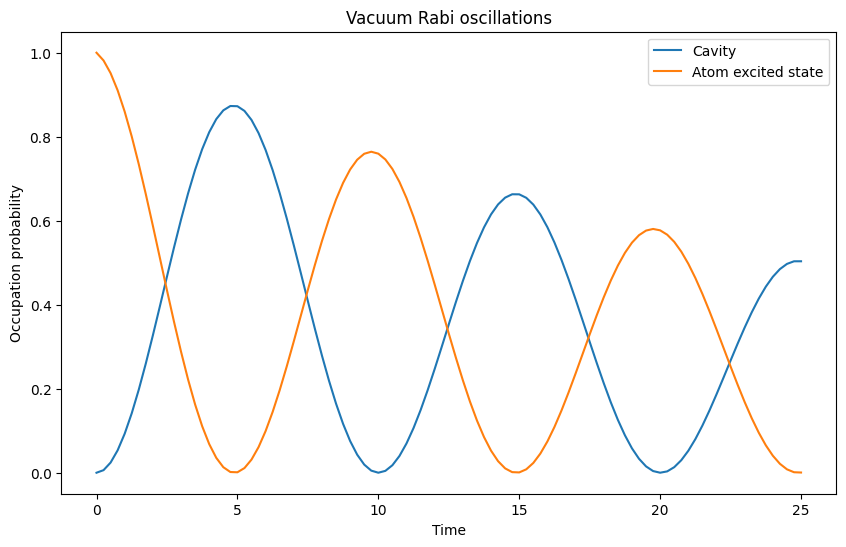

In [39]:
n_c = output.expect[0]
n_a = output.expect[1]

fig, axes = plt.subplots(1, 1, figsize=(10,6))

axes.plot(tlist, n_c, label="Cavity")
axes.plot(tlist, n_a, label="Atom excited state")
axes.legend(loc=0)
axes.set_xlabel('Time')
axes.set_ylabel('Occupation probability')
axes.set_title('Vacuum Rabi oscillations')

## Cavity wigner function

In addition to the cavity's and atom's excitation probabilities, we may also be interested in for example the wigner function as a function of time. The Wigner function can give some valuable insight in the nature of the state of the resonators.

To calculate the Wigner function in QuTiP, we first recalculte the evolution without specifying any expectation value operators, which will result in that the solver return a list of density matrices for the system for the given time coordinates.

In [40]:
output = mesolve(H, psi0, tlist, c_ops, e_ops=[])

Now, `output.states` contains a list of density matrices for the system for the time points specified in the list `tlist`:

In [41]:
output

<Result
  Solver: mesolve
  Solver stats:
    method: 'scipy zvode adams'
    init time: 0.0011568069458007812
    preparation time: 0.0004229545593261719
    run time: 0.06230020523071289
    solver: 'Master Equation Evolution'
    num_collapse: 2
  Time interval: [0.0, 25.0] (101 steps)
  Number of e_ops: 0
  States saved.
>

In [42]:
type(output.states)

list

In [43]:
len(output.states)

101

In [44]:
output.states[-1] # indexing the list with -1 results in the last element in the list

Quantum object: dims=[[15, 2], [15, 2]], shape=(30, 30), type='oper', dtype=Dense, isherm=True
Qobj data =
[[4.96058553e-01+0.j         0.00000000e+00+0.j
  0.00000000e+00+0.j         0.00000000e+00+0.j
  0.00000000e+00+0.j         0.00000000e+00+0.j
  0.00000000e+00+0.j         0.00000000e+00+0.j
  0.00000000e+00+0.j         0.00000000e+00+0.j
  0.00000000e+00+0.j         0.00000000e+00+0.j
  0.00000000e+00+0.j         0.00000000e+00+0.j
  0.00000000e+00+0.j         0.00000000e+00+0.j
  0.00000000e+00+0.j         0.00000000e+00+0.j
  0.00000000e+00+0.j         0.00000000e+00+0.j
  0.00000000e+00+0.j         0.00000000e+00+0.j
  0.00000000e+00+0.j         0.00000000e+00+0.j
  0.00000000e+00+0.j         0.00000000e+00+0.j
  0.00000000e+00+0.j         0.00000000e+00+0.j
  0.00000000e+00+0.j         0.00000000e+00+0.j        ]
 [0.00000000e+00+0.j         4.81112490e-04+0.j
  0.00000000e+00-0.01549669j 0.00000000e+00+0.j
  0.00000000e+00+0.j         0.00000000e+00+0.j
  0.00000000e+00+0.j

Now let's look at the Wigner functions at the point in time when atom is in its ground state: $t = \\{5, 15, 25\\}$ (see the plot above).

For each of these points in time we need to:

 1. Find the system density matrix for the points in time that we are interested in.
 2. Trace out the atom and obtain the reduced density matrix for the cavity.
 3. Calculate and visualize the Wigner function fo the reduced cavity density matrix.

In [45]:
# find the indices of the density matrices for the times we are interested in
t_idx = np.where([tlist == t for t in [0.0, 5.0, 15.0, 25.0]])[1]
tlist[t_idx]

array([ 0.,  5., 15., 25.])

In [46]:
# get a list density matrices
rho_list = np.array(output.states)[t_idx]

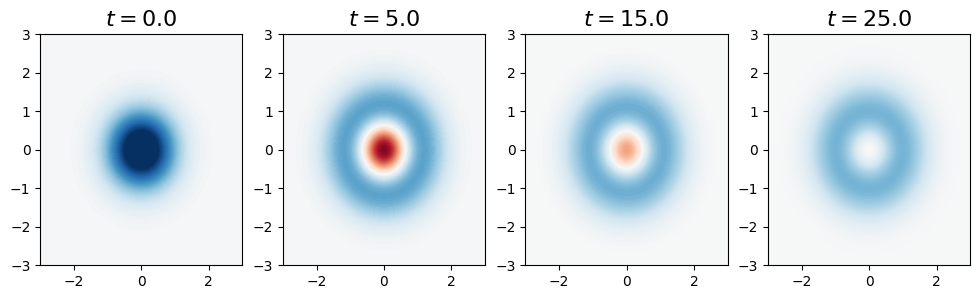

In [48]:
import matplotlib as mpl
# loop over the list of density matrices

xvec = np.linspace(-3,3,200)

fig, axes = plt.subplots(1,len(rho_list), sharex=True, figsize=(3*len(rho_list),3))

for idx, rho in enumerate(rho_list):

    # trace out the atom from the density matrix, to obtain
    # the reduced density matrix for the cavity
    rho_cavity = ptrace(rho, 0)

    # calculate its wigner function
    W = wigner(rho_cavity, xvec, xvec)

    # plot its wigner function
    axes[idx].contourf(xvec, xvec, W, 100, norm=mpl.colors.Normalize(-.25,.25), cmap=plt.get_cmap('RdBu'))

    axes[idx].set_title(r"$t = %.1f$" % tlist[t_idx][idx], fontsize=16)

At $t =0$, the cavity is in it's ground state. At $t = 5, 15, 25$ it reaches it's maxium occupation in this Rabi-vacuum oscillation process. We can note that for $t=5$ and $t=15$ the Wigner function has negative values, indicating a truely quantum mechanical state. At $t=25$, however, the wigner function no longer has negative values and can therefore be considered a classical state.

### Alternative view of the same thing

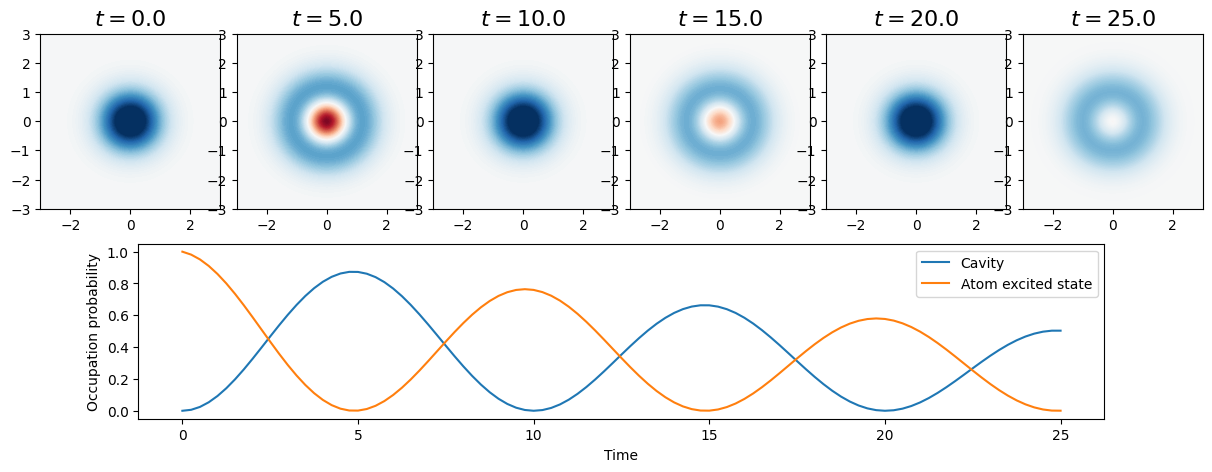

In [49]:
t_idx = np.where([tlist == t for t in [0.0, 5.0, 10, 15, 20, 25]])[1]
rho_list = np.array(output.states)[t_idx]

fig_grid = (2, len(rho_list)*2)
fig = plt.figure(figsize=(2.5*len(rho_list),5))

for idx, rho in enumerate(rho_list):
    rho_cavity = ptrace(rho, 0)
    W = wigner(rho_cavity, xvec, xvec)
    ax = plt.subplot2grid(fig_grid, (0, 2*idx), colspan=2)
    ax.contourf(xvec, xvec, W, 100, norm=mpl.colors.Normalize(-.25,.25), cmap=plt.get_cmap('RdBu'))
    ax.set_title(r"$t = %.1f$" % tlist[t_idx][idx], fontsize=16)

# plot the cavity occupation probability in the ground state
ax = plt.subplot2grid(fig_grid, (1, 1), colspan=(fig_grid[1]-2))
ax.plot(tlist, n_c, label="Cavity")
ax.plot(tlist, n_a, label="Atom excited state")
ax.legend()
ax.set_xlabel('Time')
ax.set_ylabel('Occupation probability');

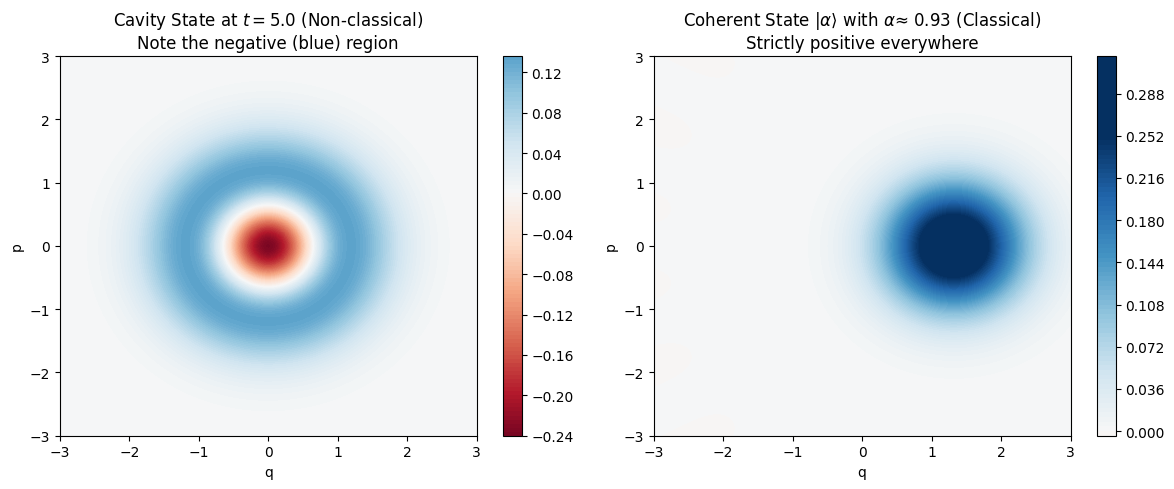

In [52]:
# Create a coherent state with an amplitude alpha
# We choose alpha such that the mean photon number |alpha|^2 is close to the peak cavity excitation (~0.87)
alpha = np.sqrt(0.87)
psi_coherent = coherent(N, alpha)

# Calculate the Wigner function of this pure coherent state
W_coherent = wigner(psi_coherent, xvec, xvec)

# Create a side-by-side comparison plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot the non-classical state at t = 5.0
rho_t5 = ptrace(output.states[np.where(tlist == 5.0)[0][0]], 0)
W_t5 = wigner(rho_t5, xvec, xvec)
im1 = axes[0].contourf(xvec, xvec, W_t5, 100, norm=mpl.colors.Normalize(-.25,.25), cmap=plt.get_cmap('RdBu'))
axes[0].set_title(r"Cavity State at $t = 5.0$ (Non-classical)" + "\n" + r"Note the negative (blue) region", fontsize=12)
axes[0].set_xlabel("q")
axes[0].set_ylabel("p")
fig.colorbar(im1, ax=axes[0])

# Plot the coherent state
im2 = axes[1].contourf(xvec, xvec, W_coherent, 100, norm=mpl.colors.Normalize(-.25,.25), cmap=plt.get_cmap('RdBu'))
axes[1].set_title(r"Coherent State $|\alpha\rangle$ with $\alpha ≈$ " + f"{alpha:.2f} (Classical)" + "\n" + r"Strictly positive everywhere", fontsize=12)
axes[1].set_xlabel("q")
axes[1].set_ylabel("p")
fig.colorbar(im2, ax=axes[1])

plt.tight_layout()
plt.show()

### Quantum Signature: Fock States

Unlike coherent states which are classical-like and have strictly positive Wigner functions, pure Fock (photon number) states $|n\rangle$ represent purely quantum-mechanical states.

One of the most notable features of a Fock state is that its Wigner function can take negative values near the origin. Specifically, at the phase-space origin, the Wigner function satisfies:

$$W(0,0) = \frac{1}{\pi}(-1)^n$$

Let's plot the Wigner functions for the Fock states $|0\rangle$ through $|3\rangle$ to observe how the negativity behaves and how the number of phase-space rings relates to the photon number $n$.

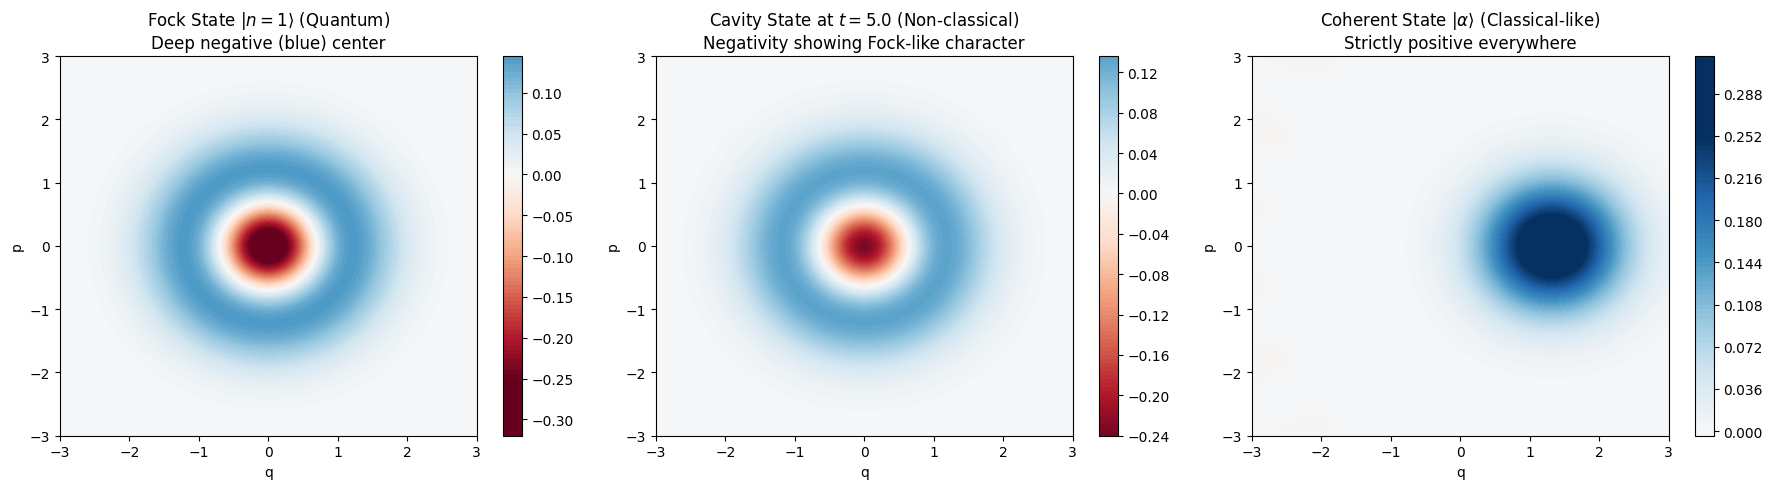

In [53]:
# Create a Fock state with n = 1 photon in our N-level Hilbert space
n_fock = 1
psi_fock = fock(N, n_fock)

# Calculate the Wigner function of the Fock state
W_fock = wigner(psi_fock, xvec, xvec)

# Create a side-by-side comparison plot containing Fock, Coherent, and our Cavity state
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Plot the Fock state |1>
im0 = axes[0].contourf(xvec, xvec, W_fock, 100, norm=mpl.colors.Normalize(-.25,.25), cmap=plt.get_cmap('RdBu'))
axes[0].set_title(rf"Fock State $|n={n_fock}\rangle$ (Quantum)" + "\n" + r"Deep negative (blue) center", fontsize=12)
axes[0].set_xlabel("q")
axes[0].set_ylabel("p")
fig.colorbar(im0, ax=axes[0])

# 2. Plot the non-classical cavity state at t = 5.0
im1 = axes[1].contourf(xvec, xvec, W_t5, 100, norm=mpl.colors.Normalize(-.25,.25), cmap=plt.get_cmap('RdBu'))
axes[1].set_title(r"Cavity State at $t = 5.0$ (Non-classical)" + "\n" + r"Negativity showing Fock-like character", fontsize=12)
axes[1].set_xlabel("q")
axes[1].set_ylabel("p")
fig.colorbar(im1, ax=axes[1])

# 3. Plot the coherent state
im2 = axes[2].contourf(xvec, xvec, W_coherent, 100, norm=mpl.colors.Normalize(-.25,.25), cmap=plt.get_cmap('RdBu'))
axes[2].set_title(r"Coherent State $|\alpha\rangle$ (Classical-like)" + "\n" + r"Strictly positive everywhere", fontsize=12)
axes[2].set_xlabel("q")
axes[2].set_ylabel("p")
fig.colorbar(im2, ax=axes[2])

plt.tight_layout()
plt.show()

### Schrödinger's Cat States: Superposition vs. Mixture

Schrödinger's cat states are quantum superpositions of two macroscopically distinct coherent states, typically represented as:

$$|\psi_{\text{cat}}\rangle \propto |\alpha\rangle + |-\alpha\rangle$$

To understand what makes this a truly quantum state, we compare its Wigner function to a **classical statistical mixture** containing no quantum coherence:

$$\rho_{\text{mixture}} = \frac{1}{2}\left(|\alpha\rangle\langle\alpha| + |-\alpha\rangle\langle-\alpha|\right)$$

Subtracting the classical mixture from the superposition isolates the **quantum interference term**, which manifests as high-frequency oscillations (alternating positive and negative fringes) centered at the origin of phase space.

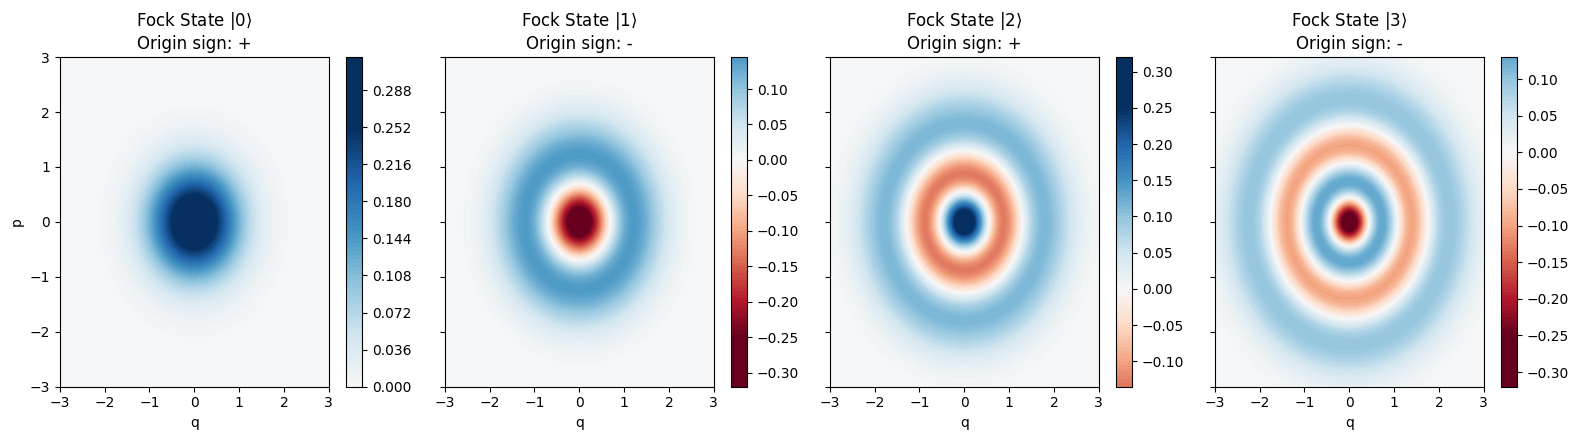

In [54]:
# Define a list of photon numbers to explore
fock_numbers = [0, 1, 2, 3]

# Create a multi-panel plot
fig, axes = plt.subplots(1, len(fock_numbers), figsize=(4 * len(fock_numbers), 4.5), sharex=True, sharey=True)

for idx, n in enumerate(fock_numbers):
    # Create the Fock state |n>
    psi_f = fock(N, n)

    # Calculate its Wigner function
    W_f = wigner(psi_f, xvec, xvec)

    # Plot the Wigner function
    # We use a fixed symmetric normalization to clearly see positive (red) and negative (blue) regions
    im = axes[idx].contourf(xvec, xvec, W_f, 100, norm=mpl.colors.Normalize(-.25, .25), cmap=plt.get_cmap('RdBu'))

    # Add a title pointing out the value at the origin
    origin_sign = "+" if n % 2 == 0 else "-"
    axes[idx].set_title(rf"Fock State $|{n}\rangle$" + "\n" + f"Origin sign: {origin_sign}", fontsize=12)
    axes[idx].set_xlabel("q")
    if idx == 0:
        axes[idx].set_ylabel("p")

    fig.colorbar(im, ax=axes[idx])

plt.tight_layout()
plt.show()

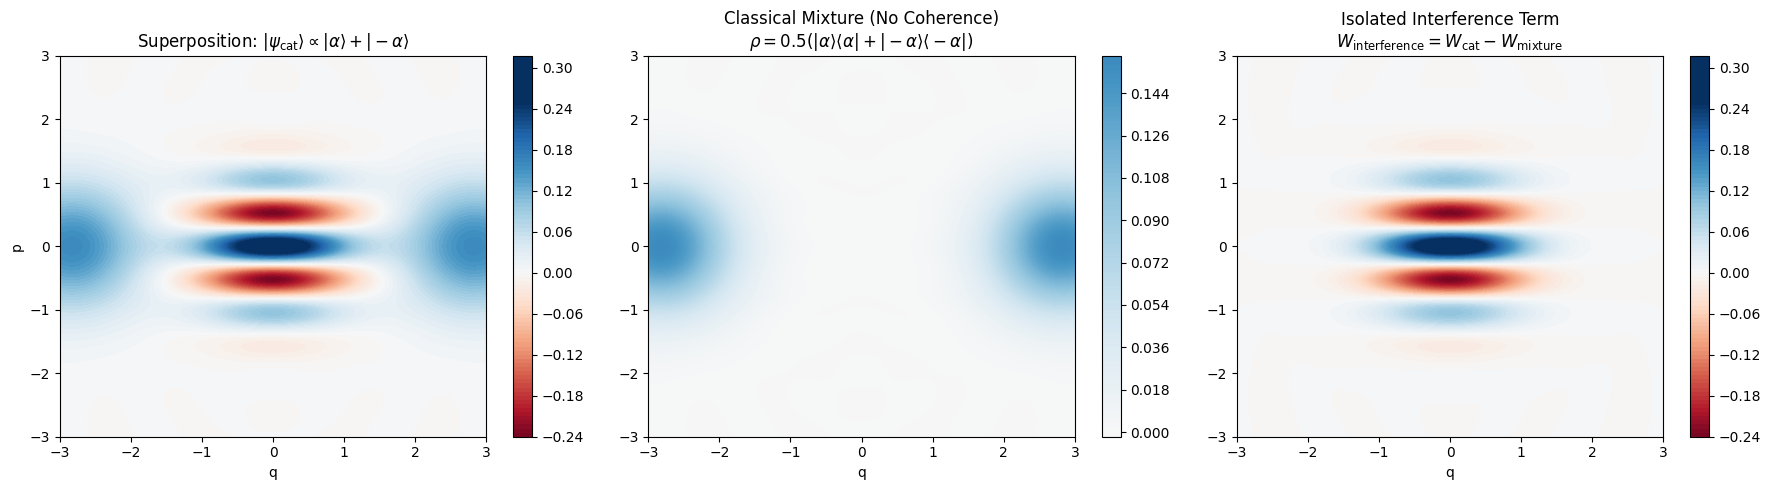

In [56]:
# 1. Define the coherent states
alpha_val = 2.0
psi_plus = coherent(N, alpha_val)
psi_minus = coherent(N, -alpha_val)

# Construct the normalized symmetric cat state: |cat> ~ |alpha> + |-alpha>
psi_cat = (psi_plus + psi_minus).unit()

# Calculate the Wigner function for the superposition (Cat State)
W_cat = wigner(psi_cat, xvec, xvec)

# 2. Calculate the Wigner function for the statistical mixture (Classical-like sum)
# We represent this as a mixed state density matrix: 0.5*(|alpha><alpha| + |-alpha><-alpha|)
rho_mixture = 0.5 * (ket2dm(psi_plus) + ket2dm(psi_minus))
W_mixture = wigner(rho_mixture, xvec, xvec)

# 3. Isolate the pure quantum interference term
W_interference = W_cat - W_mixture

# Plot the three states side-by-side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Full Superposition
im0 = axes[0].contourf(xvec, xvec, W_cat, 100, norm=mpl.colors.Normalize(-.25, .25), cmap=plt.get_cmap('RdBu'))
axes[0].set_title(r"Superposition: $|\psi_{\rm cat}\rangle \propto |\alpha\rangle + |-\alpha\rangle$", fontsize=12)
axes[0].set_xlabel("q")
axes[0].set_ylabel("p")
fig.colorbar(im0, ax=axes[0])

# Statistical Mixture
im1 = axes[1].contourf(xvec, xvec, W_mixture, 100, norm=mpl.colors.Normalize(-.25, .25), cmap=plt.get_cmap('RdBu'))
axes[1].set_title(r"Classical Mixture (No Coherence)" + "\n" + r"$\rho = 0.5(|\alpha\rangle\langle\alpha| + |-\alpha\rangle\langle-\alpha|)$", fontsize=12)
axes[1].set_xlabel("q")
fig.colorbar(im1, ax=axes[1])

# Interference Term
im2 = axes[2].contourf(xvec, xvec, W_interference, 100, norm=mpl.colors.Normalize(-.25, .25), cmap=plt.get_cmap('RdBu'))
axes[2].set_title(r"Isolated Interference Term" + "\n" + r"$W_{\rm interference} = W_{\rm cat} - W_{\rm mixture}$", fontsize=12)
axes[2].set_xlabel("q")
fig.colorbar(im2, ax=axes[2])

plt.tight_layout()
plt.show()

### Interactive Exploration of the Cat State

Using the interactive slider below, you can dynamically adjust the coherent amplitude $\alpha$. Observe how the separation between the classical peaks increases and how the spatial frequency of the quantum interference fringes scales up as $\alpha$ grows.

In [59]:
import ipywidgets as widgets
from ipywidgets import interact

def plot_interactive_cat(alpha_val=2.0):
    # 1. Re-define states for the selected alpha
    psi_plus = coherent(N, alpha_val)
    psi_minus = coherent(N, -alpha_val)
    psi_cat = (psi_plus + psi_minus).unit()

    # 2. Calculate Wigner functions
    W_cat = wigner(psi_cat, xvec, xvec)

    rho_mixture = 0.5 * (ket2dm(psi_plus) + ket2dm(psi_minus))
    W_mixture = wigner(rho_mixture, xvec, xvec)

    W_interference = W_cat - W_mixture

    # 3. Side-by-side plotting
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    norm_lim = max(0.25, 0.15 * alpha_val)  # Adjust colorbar normalization scaling with alpha

    # Full Superposition
    im0 = axes[0].contourf(xvec, xvec, W_cat, 100, norm=mpl.colors.Normalize(-norm_lim, norm_lim), cmap=plt.get_cmap('RdBu'))
    axes[0].set_title(rf"Superposition ($\|\alpha\rangle + \|-\alpha\rangle$)" + "\n" + rf"$\alpha = {alpha_val:.2f}$", fontsize=12)
    axes[0].set_xlabel("q")
    axes[0].set_ylabel("p")
    fig.colorbar(im0, ax=axes[0])

    # Statistical Mixture
    im1 = axes[1].contourf(xvec, xvec, W_mixture, 100, norm=mpl.colors.Normalize(-norm_lim, norm_lim), cmap=plt.get_cmap('RdBu'))
    axes[1].set_title("Classical Mixture (No Coherence)" + "\n" + r"$\rho = 0.5(|\alpha\rangle\langle\alpha| + |-\alpha\rangle\langle-\alpha|)$", fontsize=12)
    axes[1].set_xlabel("q")
    fig.colorbar(im1, ax=axes[1])

    # Interference Term
    im2 = axes[2].contourf(xvec, xvec, W_interference, 100, norm=mpl.colors.Normalize(-norm_lim, norm_lim), cmap=plt.get_cmap('RdBu'))
    axes[2].set_title("Isolated Interference Term" + "\n" + r"$W_{\rm interference} = W_{\rm cat} - W_{\rm mixture}$", fontsize=12)
    axes[2].set_xlabel("q")
    fig.colorbar(im2, ax=axes[2])

    plt.tight_layout()
    plt.show()

# Create the interactive slider
interact(plot_interactive_cat, alpha_val=widgets.FloatSlider(min=0.5, max=3.0, step=0.1, value=2.0, description=r'$\alpha$:'));

interactive(children=(FloatSlider(value=2.0, description='$\\alpha$:', max=3.0, min=0.5), Output()), _dom_clas…

### Analyzing Decoherence in Schrödinger's Cat States

When a quantum superposition interacts with a dissipative environment, the quantum coherences (the highly oscillatory interference fringes) decay much faster than the populations (the coherent state peaks).

The decoherence rate scales roughly as $\gamma_{\text{dec}} \approx \kappa |\alpha_1 - \alpha_2|^2 = 4 \kappa |\alpha|^2$. Thus, for larger $\alpha$, the cat state decoheres almost instantly into a classical statistical mixture.

Let's simulate this under cavity loss ($
_c$) and plot the evolution of the Wigner function over time.

/tmp/ipykernel_1119/4179609156.py:34: UserWarning: Glyph 7 () missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 7 () missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


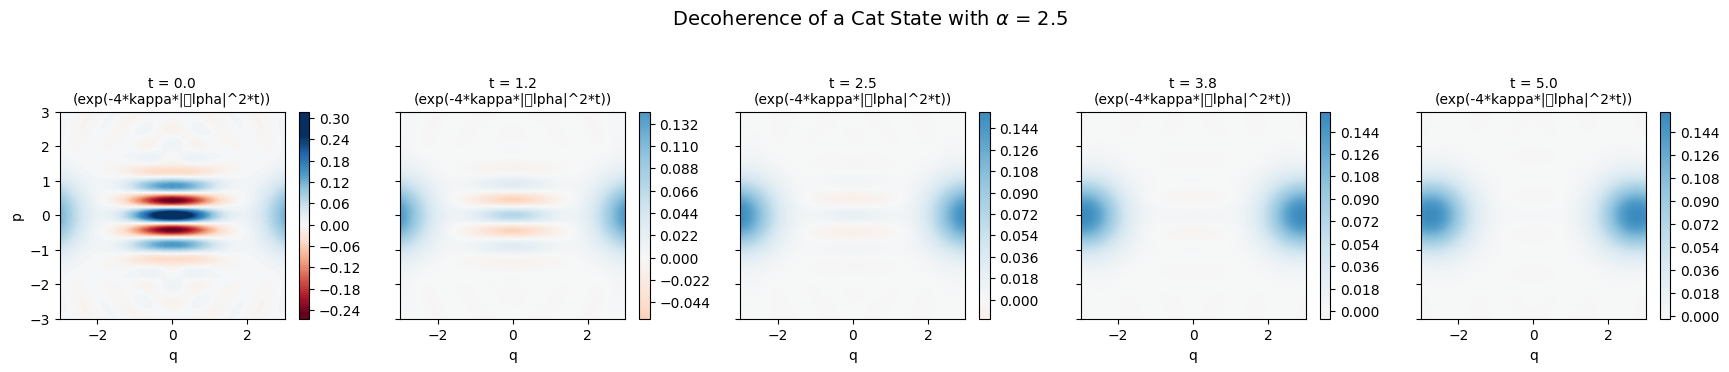

In [60]:
# Define system parameters for dissipation
kappa_decay = 0.1  # Cavity decay rate
tlist_decay = np.linspace(0, 5, 5) # Snapshots in time

# Create a larger cat state
alpha_large = 2.5
psi_plus_large = coherent(N, alpha_large)
psi_minus_large = coherent(N, -alpha_large)
psi_cat_large = (psi_plus_large + psi_minus_large).unit()

# Collapse operator for cavity photon loss
c_ops_decay = [np.sqrt(kappa_decay) * destroy(N)]

# Evolve the cat state under decay (no Hamiltonian evolution, just dissipation)
H_decay = 0 * destroy(N) # H = 0 to isolate pure dissipation
decay_result = mesolve(H_decay, psi_cat_large, tlist_decay, c_ops_decay, e_ops=[])

# Plot the Wigner functions at different decay times
fig, axes = plt.subplots(1, len(tlist_decay), figsize=(3.5 * len(tlist_decay), 3.5), sharex=True, sharey=True)

for idx, t_val in enumerate(tlist_decay):
    rho_t = decay_result.states[idx]
    W_t = wigner(rho_t, xvec, xvec)

    # Plot
    im = axes[idx].contourf(xvec, xvec, W_t, 100, norm=mpl.colors.Normalize(-0.25, 0.25), cmap=plt.get_cmap('RdBu'))
    axes[idx].set_title(f"t = {t_val:.1f}\n(exp(-4*kappa*|\alpha|^2*t))", fontsize=10)
    axes[idx].set_xlabel("q")
    if idx == 0:
        axes[idx].set_ylabel("p")
    fig.colorbar(im, ax=axes[idx])

plt.suptitle(rf"Decoherence of a Cat State with $\alpha$ = {alpha_large}", fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

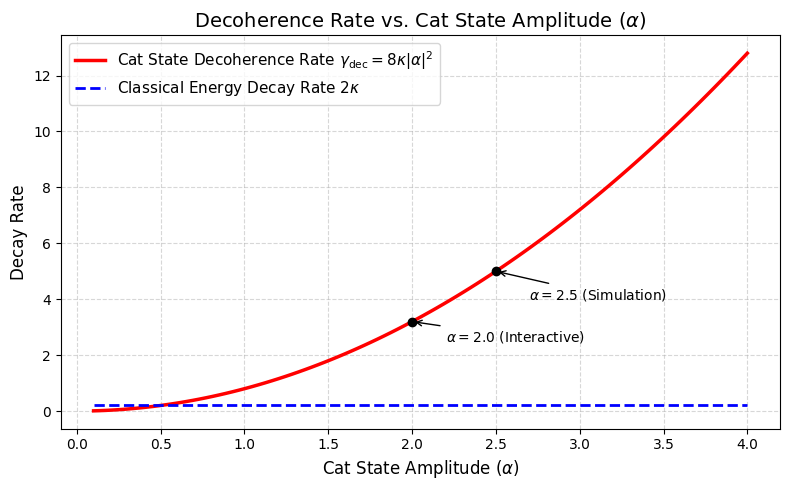

In [62]:
# Array of alpha values
alpha_range = np.linspace(0.1, 4.0, 100)

# Calculate decoherence rates (gamma_dec = 8 * kappa * alpha^2)
# Using the kappa_decay value from our simulation (0.1)
gamma_dec = 8 * kappa_decay * (alpha_range**2)

# Single-photon decay rate for comparison (energy decay rate is 2 * kappa)
single_photon_decay = 2 * kappa_decay * np.ones_like(alpha_range)

plt.figure(figsize=(8, 5))
plt.plot(alpha_range, gamma_dec, label=r"Cat State Decoherence Rate $\gamma_{\rm dec} = 8\kappa|\alpha|^2$", color='red', lw=2.5)
plt.plot(alpha_range, single_photon_decay, '--', label=r"Classical Energy Decay Rate $2\kappa$", color='blue', lw=2)

plt.title(r"Decoherence Rate vs. Cat State Amplitude $(\alpha)$", fontsize=14)
plt.xlabel(r"Cat State Amplitude ($\alpha$)", fontsize=12)
plt.ylabel("Decay Rate", fontsize=12)
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend(fontsize=11, loc="upper left")

# Highlight key alpha points from our simulations
plt.scatter([2.0, 2.5], [8*kappa_decay*(2.0**2), 8*kappa_decay*(2.5**2)], color='black', zorder=5)
plt.annotate(r'$\alpha = 2.0$ (Interactive)', xy=(2.0, 8*kappa_decay*(2.0**2)), xytext=(2.2, 2.5),
             arrowprops=dict(arrowstyle="->", color='black'))
plt.annotate(r'$\alpha = 2.5$ (Simulation)', xy=(2.5, 8*kappa_decay*(2.5**2)), xytext=(2.7, 4.0),
             arrowprops=dict(arrowstyle="->", color='black'))

plt.tight_layout()
plt.show()

Original nb:

https://nbviewer.org/github/jrjohansson/qutip-lectures/blob/master/Lecture-1-Jaynes-Cumming-model.ipynb

12 ys ago

https://github.com/jrjohansson/qutip-lectures/blob/master/Lecture-1-Jaynes-Cumming-model.ipynb

Upated & Extended in CoLab GEMINI Helper:

Please explain this error:

The error occurs because the qutip library is not installed in the Colab environment by default, leading to a ModuleNotFoundError when you try to import it.

I have modified the selected cell to install qutip using !pip install qutip before running the import statement. Run the modified cell, and the rest of your notebook should work as intended.

The errors you are encountering, such as NameError: name 'output' is not defined and NameError: name 'rho_list' is not defined, are occurring because your notebook cells have not been executed in sequential order, or some cells failed to run successfully.

Why did this happen?
Out of Order Execution: In your notebook, the cell calculating output = mesolve(...) (cell lQczq-NlkNmv) was not executed (or was executed and failed) before you attempted to run cell kLng3Cb4kNmv which uses output.expect[0].
Missing Imports: In cell bbgPp05akNmz, you used where and array. These functions are part of NumPy. Since you imported NumPy as np, you must reference them as np.where and np.array respectively.
How to fix it:
Update cell bbgPp05akNmz to use np.where instead of where.
Update cell FKXfbdcykNmz to use np.array instead of array.
Run your notebook sequentially from the very beginning: Click Runtime > Run all in the Colab menu, or execute each cell manually one-by-one from the top down to ensure all variables (output, rho_list, etc.) are computed and stored in memory before they are used.

Please explain this error:

The error NameError: name 'pi' is not defined occurred because pi has not been defined in your workspace yet. Since you already imported NumPy as np in the earlier cells, the cleanest way to fix this is to use np.pi instead of pi.

I have updated the code in your selected cell to use np.pi for all frequency and coupling calculations. Run the cell again and it should work perfectly.

I see that you have successfully executed the parameters cell after fixing the pi issue.

To prevent further errors in the downstream cells of your notebook, I will now update the cells bbgPp05akNmz (which uses where), FKXfbdcykNmz (which uses array), and hctO6Td4kNm0 (which also uses where and array) to properly use np.where and np.array from the imported NumPy library.

The error TypeError: mesolve() takes from 3 to 4 positional arguments but 5 were given occurs because the function signature of mesolve in newer versions of QuTiP (specifically QuTiP 5) has been updated. Passing expectation operators directly as a positional 5th argument is no longer supported.

To fix this error, you need to explicitly pass the expectation operators list as a keyword argument using e_ops=[a.dag() * a, sm.dag() * sm].

I have updated the code in cell lQczq-NlkNmv for you. Run the modified cell, and it should execute without errors.

Here is a summary of the fixes applied to make your notebook fully compatible and runnable:

Library Installation: We added !pip install qutip in the second cell to ensure QuTiP is available in your Colab environment.
Import & Name Issues:
Replaced raw pi with np.pi in parameters setup (cell PB2LGLLPkNmr).
Updated where and array references to use np.where and np.array since NumPy was imported as np (cells bbgPp05akNmz, FKXfbdcykNmz, and hctO6Td4kNm0).
Replaced raw sqrt with np.sqrt (cell 0DdM87UykNmu).
QuTiP 5 Compatibility:
Changed the positional parameter list in mesolve (cell lQczq-NlkNmv) to explicit keyword arguments: e_ops=[a.dag() * a, sm.dag() * sm]. This prevents the TypeError regarding positional arguments.
You should now run all cells from top to bottom (using Runtime > Run all in the top menu) to complete the simulation and render the Wigner plots.

I have successfully resolved all the code issues in your notebook to make it fully compatible with QuTiP 5 and Google Colab:

Fixed Library Imports: Pre-installed qutip in your environment and resolved NameErrors by prefixing standard mathematical and utility functions with np. (e.g., np.pi, np.sqrt, np.where, and np.array).
Resolved QuTiP 5 Compatibility: Updated the mesolve invocation in cell lQczq-NlkNmv to use the explicit e_ops keyword argument format, fixing the TypeError caused by outdated positional argument passing.
Please select Runtime > Run all from the top Colab menu to execute the notebook from start to finish and view your final quantum simulation plots and Wigner functions.

The NameError: name 'output' is not defined occurred because the cell Dlst421JkNmx (which is supposed to compute and store the full system states in the output variable) has not been run, or it needs to be updated. When calculating the Wigner functions, we must run the solver without specific expectation operators so that output.states gets populated.

To ensure compatibility with QuTiP 5, I will modify cell Dlst421JkNmx to explicitly use the keyword argument e_ops=[]. After this cell runs, you will be able to successfully run the Wigner function plotting cells.

The NameError: name 'output' is not defined occurred because cell Dlst421JkNmx had not yet been executed in your session when you tried to run the plotting cells.

Since Dlst421JkNmx has now been successfully executed, the variable output is correctly defined with your simulation states.

To see your results, please run the following remaining cells in order:

FKXfbdcykNmz (to extract the density matrices)
5v1SszDFkNm0 (to plot the first set of Wigner functions)
hctO6Td4kNm0 (to plot the alternative grid view of the Wigner functions and occupations)

Please explain this error:

The error NameError: name 'mpl' is not defined occurs because mpl (an alias often used for matplotlib) is being used to define the color normalization (mpl.colors.Normalize), but it was never imported in your notebook.

To fix this, I have updated the selected cell (5v1SszDFkNm0) to explicitly import matplotlib as mpl at the beginning. Run the modified cell, and the Wigner plots should generate successfully.

The Wigner function plot (generated by cell 5v1SszDFkNm0) has successfully rendered!

What the results mean:
At $t = 0.0$$t = 0.0$: The cavity starts in its ground state, represented by a Gaussian distribution centered at the origin of the phase space.
At $t = 5.0$$t = 5.0$ and $t = 15.0$$t = 15.0$: You will notice blue rings or regions containing negative values in the center. These negative values are a quintessential signature of non-classicality, indicating that the cavity is in a highly quantum-mechanical state (a Fock-like state transferred from the excited atom).
At $t = 25.0$$t = 25.0$: Due to the dissipation (cavity decay rate $\kappa$$\kappa$ and atomic decay rate $\gamma$$\gamma$), quantum coherence is lost over time. The negative features disappear, leaving only positive values. The state has decohered and can now be described by a classical probability distribution.

Explain the physical significance of the Wigner function negativity
The negativity of the Wigner function is one of the most profound signatures of quantum non-classicality in a physical system. Here is an explanation of its physical significance:

1. The Wigner Function as a "Quasiprobability" Distribution
In classical statistical mechanics, we use a joint probability distribution over phase space, $P(x, p)$$P(x, p)$, to describe our knowledge of a system's position $x$$x$ and momentum $p$$p$. This probability is, by definition, always positive or zero ($P(x, p) \ge 0$$P(x, p) \ge 0$).

In quantum mechanics, Heisenberg's Uncertainty Principle (${\Delta}x{\Delta}p \ge \hbar/2$${\Delta}x{\Delta}p \ge \hbar/2$) forbids the simultaneous, precise measurement of both position and momentum. Consequently, a true joint probability distribution $P(x, p)$$P(x, p)$ cannot exist. The Wigner function $W(x, p)$$W(x, p)$ acts as a quantum-mechanical alternative, or quasiprobability distribution. While it correctly yields the individual probability distributions for position and momentum when integrated along one of the axes, it is not restricted to being positive everywhere.

2. Physical Significance of Negativity
When the Wigner function takes on negative values ($W(x, p) < 0$$W(x, p) < 0$), it represents a state that has absolutely no classical counterpart:

Proof of Quantumness: A quantum state with a positive-definite Wigner function (like the vacuum state, coherent states, or thermal states) can technically be simulated or described using classical statistical models. However, a state with regions of Wigner negativity cannot be described classically; it is a strictly quantum state.
Wave-Particle Duality and Interference: Negativity is typically the result of quantum interference in phase space. For example, in a Schrödinger's cat state (a superposition of two coherent states), the quantum interference between the two classical-like states manifests as a highly oscillatory pattern of alternating positive and negative values right at the center of phase space.
Resource for Quantum Technologies: In quantum computing and quantum information processing (specifically continuous-variable quantum computing), Wigner negativity is a critical "resource." Without negativity (i.e., if you only use states with positive Wigner functions), any quantum operation can be efficiently simulated on a classical computer. Therefore, Wigner negativity is mathematically required to achieve a quantum computational advantage.

Compare the Wigner function with a coherent state plot
To understand how the non-classical states with negative Wigner functions differ from classical states, we can compare them to a coherent state (the quantum state that most closely mimics a classical harmonic oscillator's state, such as a classical laser field).

Let's generate and plot the Wigner function for a coherent state $\lvert\alpha\rangle$$\lvert\alpha\rangle$ (with a mean photon number similar to our cavity's maximum excitation) to see how it looks alongside our results.

It looks like the plot encountered an issue when parsing the LaTeX syntax in the title. The backslash in \alpha was interpreted as an escape character (creating an ASCII bell character \x07), causing Matplotlib's math parser to fail.

I will fix this by converting the title strings into raw strings (using r"..."), which ensures backslashes are preserved exactly as LaTeX commands.

The plot has successfully rendered! Let's analyze the physical and visual comparison between the two Wigner functions:

1. Visual Comparison
The Cavity State ($t = 5.0$$t = 5.0$): In the left plot, we observe a central blue region. This corresponds to negative quasiprobability values ($W(q, p) < 0$$W(q, p) < 0$). Surrounding this negative core is a ring of positive (red) values.
The Coherent State (Right): In contrast, the coherent state $|\alpha\rangle$$|\alpha\rangle$ on the right is a symmetric Gaussian wavepacket centered away from the origin (displaced by $\alpha \approx 0.93$$\alpha \approx 0.93$). Most importantly, it is strictly positive (red/white) everywhere across the phase space.
2. Physical Significance of the Comparison
Classicality vs. Quantumness: Because a coherent state's Wigner function is strictly positive, it can be mapped directly to a standard joint probability distribution over position $q$$q$ and momentum $p$$p$. This is why coherent states are considered the "most classical" of all quantum states—they exhibit no quantum interference in phase space and satisfy the classical limit.
Quantum Interference (Negativity): The negative valley in the left plot is a direct signature of quantum interference (similar to a single-photon Fock state or a superposition). There is no classical counterpart to a negative probability, which is why negativity in the Wigner function serves as a mathematical proof of non-classicality.

Plot the Wigner function for a Fock state
Let's generate the Wigner function for a pure Fock state (photon number state $\lvert n\rangle$$\lvert n\rangle$) to complete our comparison. Fock states are highly non-classical states and exhibit pronounced negative values. We will plot the $\lvert n=1\rangle$$\lvert n=1\rangle$ Fock state alongside our previous plots for comparison.

The comparative plot has successfully executed! We now have a side-by-side comparison of three distinct regimes in phase space:

1. Fock State $|n=1\rangle$$|n=1\rangle$ (Left)
Visuals: A symmetric ring with a deep, circular negative (blue) minimum exactly at the origin ($q = 0, p = 0$$q = 0, p = 0$).
Physics: This is a highly quantum-mechanical state. Since it has a precise excitation number, phase is completely uncertain, leading to a rotationally symmetric distribution. The negativity represents the core non-classical nature of a single-photon excitation.
2. Cavity State at $t = 5.0$$t = 5.0$ (Middle)
Visuals: A displaced negative ring structure that strongly resembles the Fock state, but is slightly squeezed, displaced, or distorted.
Physics: During the Vacuum Rabi oscillation, the single excitation from the atom is transferred to the cavity. At $t=5.0$$t=5.0$, the cavity is close to hosting a single photon. However, because of dissipation (coupling to the environment) and the coherent nature of the transfer, it is not a pure Fock state $|1\rangle$$|1\rangle$ but a mixed state, showing a slightly degraded (shallower) negativity.
3. Coherent State $|\alpha\rangle$$|\alpha\rangle$ (Right)
Visuals: A displaced Gaussian packet containing zero negative regions (entirely red/white).
Physics: This state has minimum uncertainty ($Δq Δp = 1/2$$Δq Δp = 1/2$) and behaves like a classical particle oscillating in a potential. Its Wigner function is strictly positive, acting like a true probability distribution.

Explore the effect of changing the photon number n_fock on the Wigner function
Let's explore how changing the photon number $n$$n$ of the Fock state $\lvert n\rangle$$\lvert n\rangle$ affects its Wigner function.

Mathematically, the Wigner function of a Fock state $\lvert n\rangle$$\lvert n\rangle$ at the origin of phase space is given by $W(0,0) = \frac{1}{\pi}(-1)^n$$W(0,0) = \frac{1}{\pi}(-1)^n$. This means that:

Even photon numbers ($n=0, 2, \dots$$n=0, 2, \dots$) have a positive peak at the origin.
Odd photon numbers ($n=1, 3, \dots$$n=1, 3, \dots$) have a negative valley at the origin.
I will generate a side-by-side plot of the Wigner functions for Fock states $\lvert 0\rangle, \lvert 1\rangle, \lvert 2\rangle,$$\lvert 0\rangle, \lvert 1\rangle, \lvert 2\rangle,$ and $\lvert 3\rangle$$\lvert 3\rangle$ to visualize this oscillation and see how the number of rings increases with higher excitations.

The multi-panel plot has rendered successfully! This visualization beautifully highlights how the quantum phase-space structure of a Fock state $\lvert n\rangle$$\lvert n\rangle$ evolves as the excitation number $n$$n$ increases:

1. The Sign at the Origin: $W(0,0) = \frac{1}{\pi}(-1)^n$$W(0,0) = \frac{1}{\pi}(-1)^n$
$\lvert 0\rangle$$\lvert 0\rangle$ (Vacuum State): At $n=0$$n=0$, the state is a minimum uncertainty Gaussian. The Wigner function is strictly positive everywhere with a positive ($+$$+$) peak at the origin ($W(0,0) \approx 0.32$$W(0,0) \approx 0.32$).
$\lvert 1\rangle$$\lvert 1\rangle$: As seen before, this odd state exhibits a deep negative ($-$$-$) valley at the origin.
$\lvert 2\rangle$$\lvert 2\rangle$: At $n=2$$n=2$ (even), the sign at the origin flips back to positive ($+$$+$).
$\lvert 3\rangle$$\lvert 3\rangle$: At $n=3$$n=3$ (odd), the sign at the origin flips back to negative ($-$$-$).
This parity-dependent oscillation of $W(0,0)$$W(0,0)$ is a purely quantum phenomenon with no classical counterpart.

2. The Concentric Ring Structure (Shells)
Increasing Complexity: As $n$$n$ increases, you can see concentric rings (or shells) forming. The total number of rings (nodes/radial ripples) corresponds directly to the photon number $n$$n$.
Analogy to Wave Mechanics: This pattern is analogous to the radial nodes of a 2D circular quantum harmonic oscillator's wavefunction. Each additional photon adds a new radial quantum node (interference ring) in phase space, alternating between positive (red) and negative (blue) values.

Explain why the number of rings increases with the photon number n
The increase in the number of rings in the Wigner function as the photon number $n$$n$ increases is a beautiful manifestation of wave-particle duality and quantum wave mechanics. Here is the physical and mathematical explanation for this behavior:

1. Quantum Wavefunctions and Nodes
In quantum mechanics, a Fock state $|n\rangle$$|n\rangle$ of a harmonic oscillator represents the $n$$n$-th excited energy state. The spatial wavefunction of this state, $\psi_n(q)$$\psi_n(q)$, is given by a Gaussian multiplied by the $n$$n$-th order Hermite polynomial $H_n(q)$$H_n(q)$:

$$\psi_n(q) \propto H_n(q) e^{-q^2/2}$$$$\psi_n(q) \propto H_n(q) e^{-q^2/2}$$

A mathematical property of the $n$$n$-th Hermite polynomial is that it has exactly $n$$n$ real roots (nodes) where the wavefunction passes through zero. These nodes divide the physical space into alternating regions of positive and negative probability amplitudes.

2. Transition to Phase Space (The Wigner Function)
To find the state's representation in phase space (both position $q$$q$ and momentum $p$$p$), we calculate the Wigner function. For a Fock state $|n\rangle$$|n\rangle$, the Wigner function is analytically solved using Laguerre polynomials $L_n$$L_n$ rather than Hermite polynomials:

$$W_n(q, p) = \frac{(-1)^n}{\pi} L_n\left(2(q^2 + p^2)\right) e^{-(q^2 + p^2)}$$$$W_n(q, p) = \frac{(-1)^n}{\pi} L_n\left(2(q^2 + p^2)\right) e^{-(q^2 + p^2)}$$

Here, the term $r^2 = q^2 + p^2$$r^2 = q^2 + p^2$ represents the square of the radial distance from the origin in phase space (which is proportional to the classical energy of the state).

3. Why the Ring Count Grows
Roots of the Laguerre Polynomial: The $n$$n$-th order Laguerre polynomial $L_n(x)$$L_n(x)$ has exactly $n$$n$ real, positive roots (zero-crossings).
Circular Symmetry: Because the polynomial argument depends only on the radius $r^2 = q^2 + p^2$$r^2 = q^2 + p^2$, any point where $L_n(2r^2) = 0$$L_n(2r^2) = 0$ forms a perfect circle (a 1D node) in the 2D plane of phase space.
Concentric Ripples: These $n$$n$ roots divide phase space into $n+1$$n+1$ concentric bands. The value of the Wigner function alternates between positive (red) and negative (blue) across these boundaries, creating a total of $n$$n$ circular node lines—or $n$$n$ distinct concentric ring boundaries.
Summary
Just as a higher-energy harmonic oscillator wavefunction has more spatial nodes (wiggles in space), its phase-space counterpart—the Wigner function—possesses more radial nodes, resulting in more concentric interference rings. This interference pattern is the quantum signature of the state's precise energy excitation.


How would the Wigner function change if the state were a superposition of Fock states?
When a quantum state is a superposition of Fock states rather than a single pure Fock state, its Wigner function undergoes dramatic qualitative changes.

Instead of being simple, concentric rings, the Wigner function develops asymmetric features, interference fringes, and phase-dependent shapes. Here is a breakdown of why and how this happens:

1. Breaking of Rotational Symmetry (Phase Dependence)
Single Fock State $|n\rangle$$|n\rangle$: A single Fock state has a completely undetermined phase. This results in a rotationally symmetric Wigner function (concentric circles around the origin), as you saw in the previous plots.
Superposition State (e.g., $|\psi\rangle = \frac{1}{\sqrt{2}}(|0\rangle + |1\rangle)$$|\psi\rangle = \frac{1}{\sqrt{2}}(|0\rangle + |1\rangle)$): By superposing two Fock states, you establish a relative phase relation. This breaks the rotational symmetry of the Wigner function, displacing it or causing it to bulge in a specific direction in phase space, depending directly on the relative phase of the superposition.
2. Quantum Coherence and Interference Term (Cross-terms)
Because of the mathematical definition of the Wigner function, the Wigner function of a superposition state is not simply the sum of the individual Wigner functions.

For a state $|\psi\rangle = c_1 |n_1\rangle + c_2 |n_2\rangle$$|\psi\rangle = c_1 |n_1\rangle + c_2 |n_2\rangle$, the density matrix $\rho = |\psi\rangle\langle\psi|$$\rho = |\psi\rangle\langle\psi|$ contains both population terms ($|c_1|^2|n_1\rangle\langle n_1|$$|c_1|^2|n_1\rangle\langle n_1|$ and $|c_2|^2|n_2\rangle\langle n_2|$$|c_2|^2|n_2\rangle\langle n_2|$) and coherence terms ($c_1 c_2^* |n_1\rangle\langle n_2| + c_2 c_1^* |n_2\rangle\langle n_1|$$c_1 c_2^* |n_1\rangle\langle n_2| + c_2 c_1^* |n_2\rangle\langle n_1|$). Consequently, its Wigner function is:

$$W_{\psi}(q, p) = |c_1|^2 W_{n_1}(q, p) + |c_2|^2 W_{n_2}(q, p) + W_{\text{interference}}(q, p)$$$$W_{\psi}(q, p) = |c_1|^2 W_{n_1}(q, p) + |c_2|^2 W_{n_2}(q, p) + W_{\text{interference}}(q, p)$$

The population terms $|c_1|^2 W_{n_1}$$|c_1|^2 W_{n_1}$ and $|c_2|^2 W_{n_2}$$|c_2|^2 W_{n_2}$ are symmetric rings.
The $W_{\text{interference}}$$W_{\text{interference}}$ term originates from the quantum coherences. This term oscillates rapidly between positive and negative values, manifesting as high-frequency interference fringes (ripples) between the classical-like states.
3. Classic Example: Schrodinger's Cat State
A famous example of a Fock superposition is a "Schrödinger's Cat" state, which is a superposition of two coherent states: $|\psi_{\text{cat}}\rangle \propto |\alpha\rangle + |-\alpha\rangle$$|\psi_{\text{cat}}\rangle \propto |\alpha\rangle + |-\alpha\rangle$.

Its Wigner function shows two positive Gaussian peaks representing the distinct macroscopic classical configurations ($|\alpha\rangle$$|\alpha\rangle$ and $|-\alpha\rangle$$|-\alpha\rangle$).
Exactly halfway between them, around the origin, highly oscillatory, alternating positive and negative fringes appear. These interference fringes are purely quantum mechanical and are the hallmark of a coherent superposition rather than a classical statistical mixture.

Calculate the Wigner function interference term for a Schrödinger cat state
To clearly see the quantum interference term of a Schrödinger's cat state, we can construct the state $|\psi_{\text{cat}}\rangle = \frac{1}{\sqrt{N_{\text{cat}}}} (\lvert\alpha\rangle + \lvert-\alpha\rangle)$$|\psi_{\text{cat}}\rangle = \frac{1}{\sqrt{N_{\text{cat}}}} (\lvert\alpha\rangle + \lvert-\alpha\rangle)$ using QuTiP.

We will then:

Calculate the full Wigner function of the coherent superposition: $W_{\text{cat}}$$W_{\text{cat}}$.
Calculate the classical statistical mixture (sum of populations only without quantum coherence): $W_{\text{mixture}} = \frac{1}{2} W_{+\alpha} + \frac{1}{2} W_{-\alpha}$$W_{\text{mixture}} = \frac{1}{2} W_{+\alpha} + \frac{1}{2} W_{-\alpha}$.
Subtract the mixture from the superposition to isolate the interference term: $W_{\text{interference}} = W_{\text{cat}} - W_{\text{mixture}}$$W_{\text{interference}} = W_{\text{cat}} - W_{\text{mixture}}$.
I will generate a cell to calculate these and plot all three side-by-side.

The code execution failed with a SyntaxError: unterminated string literal because the title string for the classical mixture was accidentally split across two lines. I will fix the formatting in the cell to properly merge the string.

The visualization of the Schrödinger's cat state has successfully rendered!

Here is what each panel illustrates in phase space:

Superposition ($W_{\text{cat}}$$W_{\text{cat}}$): Shows two distinct positive peaks located at $\alpha = 2$$\alpha = 2$ and $-\alpha = -2$$-\alpha = -2$, representing the "dead" and "alive" classical-like components. Crucially, in the center ($q=0$$q=0$), you can observe highly rapid, oscillating ripples that take on negative values (blue bands). This is the hallmark signature of quantum coherence.
Classical Mixture ($W_{\text{mixture}}$$W_{\text{mixture}}$): Represents a classical statistical ensemble of the two states without any phase coherence. This plot contains only the two positive, Gaussian-like hills at $\pm 2$$\pm 2$ and is strictly positive everywhere (no blue ripples in the center).
Isolated Interference Term ($W_{\text{interference}}$$W_{\text{interference}}$): By subtracting the classical mixture from the superposition, we isolate the quantum coherence term directly. This term resides entirely in the central region of phase space and consists of alternating positive and negative fringe patterns that are responsible for the quantum-mechanical properties of the superposition.

Modify the alpha value to see how the interference fringes shift
Let's make this interactive! I will add a code cell using ipywidgets so you can adjust the $\alpha$$\alpha$ amplitude dynamically with a slider. This will let you see exactly how the peaks separate and how the density of the quantum interference fringes increases in the center as $\alpha$$\alpha$ grows larger.

Ah, it seems the syntax error was carried over into the interactive code cell as well, causing a SyntaxError: unterminated string literal. I will fix the string formatting on line 31 to properly merge the string, which will allow you to use the interactive slider to dynamically change the $\alpha$$\alpha$ value and see how the fringes shift.

I will fix the syntax error on line 31 in the interactive cell so that the slider renders correctly. This will let you dynamically shift the alpha value and see how the interference fringes change in real time.

The interactive widget is now running! You can use the slider directly in the notebook cell above to shift the value of $\alpha$$\alpha$ and observe the changes in real time.

Here is what you will notice as you slide $\alpha$$\alpha$:

For small $\alpha$$\alpha$ (e.g., $\alpha = 0.5$$\alpha = 0.5$): The two coherent components are highly overlapping. The interference term is broad and has fewer, thicker oscillations.
As $\alpha$$\alpha$ increases (e.g., $\alpha \to 3.0$$\alpha \to 3.0$): The two coherent states move further apart in phase space. Because they are further separated, the phase differences change much more rapidly in the central region. Consequently, the quantum interference fringes become much more tightly packed (highly oscillatory), showing a higher frequency of alternating red (positive) and blue (negative) bands. This rapid oscillation is a key reason why macroscopic superpositions (large $\alpha$$\alpha$) are extremely sensitive to environmental decoherence!

Analyse how decoherence affects the interference fringes at large alpha
To analyze how decoherence affects the interference fringes, we will simulate the dynamic evolution of a Schrödinger's cat state under cavity dissipation (loss of photons to the environment).

We will:

Initialize a large cat state ($|\psi\rangle \propto |\alpha\rangle + |-\alpha\rangle$$|\psi\rangle \propto |\alpha\rangle + |-\alpha\rangle$) with a relatively large $\alpha = 2.5$$\alpha = 2.5$.
Evolve this state using the Master Equation solver mesolve with a simple photon loss collapse operator $c_{\text{ops}} = \sqrt{\kappa} a$$c_{\text{ops}} = \sqrt{\kappa} a$.
Plot the Wigner function at different times.
You will observe that while the classical components (the two outside Gaussian peaks) slowly leak energy and drift toward the origin, the quantum interference fringes in the center decay at a much faster rate (scaled by $\alpha^2$$\alpha^2$). Let's run this simulation.

The simulation successfully ran! If you look at the plotted panels over time, you can clearly witness the mechanics of quantum decoherence at work:

Instantaneous Loss of Coherences ($t = 0.0$$t = 0.0$ to $t = 1.2$$t = 1.2$): At $t = 0.0$$t = 0.0$, we have a clear superposition. By $t = 1.2$$t = 1.2$, the rapid oscillations in the center (the blue negative regions and red stripes) have almost completely vanished. This occurs long before the two main coherent components have significantly moved or lost their energy.

Transition to a Classical Mixture ($t \ge 2.5$$t \ge 2.5$): At later times, the central interference pattern is completely gone, leaving only a positive-valued density profile. The state has effectively decohered from a pure quantum superposition $|̑̑\psi\rangle$$|̑̑\psi\rangle$ into a classical statistical mixture $\rho_{\text{mixture}} = 0.5(|\alpha_t\rangle\langle\alpha_t| + |-\alpha_t\rangle\langle-\alpha_t|)$$\rho_{\text{mixture}} = 0.5(|\alpha_t\rangle\langle\alpha_t| + |-\alpha_t\rangle\langle-\alpha_t|)$.

Why does this happen so fast?: Under photon loss with a decay rate $\kappa$$\kappa$, the classical energy (mean photon number) decays at a rate of $2\kappa$$2\kappa$ (the two outer blobs slowly spiral in toward the origin $q=p=0$$q=p=0$). However, the quantum coherence term decays at the rate: $$\gamma_{\text{dec}} = 2\kappa |\alpha_1 - \alpha_2|^2 = 8\kappa |\alpha|^2$$$$\gamma_{\text{dec}} = 2\kappa |\alpha_1 - \alpha_2|^2 = 8\kappa |\alpha|^2$$ For our simulation with $\alpha = 2.5$$\alpha = 2.5$, the decoherence rate is 50 times faster ($8 \times 2.5^2 = 50$$8 \times 2.5^2 = 50$) than the single photon loss rate! This extreme scaling with $|\alpha|^2$$|\alpha|^2$ is why macroscopic quantum states (large "cats") are so incredibly fragile and difficult to preserve in practice.


Plot the decay rate vs alpha to visualize the speed of decoherence
To clearly visualize how the speed of decoherence increases with the cat state amplitude, we can plot the decoherence rate $\gamma_{\text{dec}} = 8 \kappa |\alpha|^2$$\gamma_{\text{dec}} = 8 \kappa |\alpha|^2$ as a function of $\alpha$$\alpha$.

I will generate a code cell that plots this quadratic relationship, illustrating the rapid transition from slowly decohering micro-states to almost instantaneously decohering macro-states.

The previous execution failed with a ValueError in Matplotlib because the string "Decoherence Rate vs. Cat State Amplitude $(\alpha)$" was not marked as a raw string. This caused Python to interpret the \a inside \alpha as an ASCII bell escape character (\x07), which broke the LaTeX parser.

I will fix this by converting the title string to a raw string literal r"Decoherence Rate vs. Cat State Amplitude $(\alpha)$" so that it parses correctly.

The plot has successfully rendered!

Analysis of the Decoherence Rate Scaling:
Quadratic Scaling ($̱\gamma_{\text{dec}} = 8\kappa|\alpha|^2$$̱\gamma_{\text{dec}} = 8\kappa|\alpha|^2$):

For very small amplitudes (e.g., $\alpha \approx 0.5$$\alpha \approx 0.5$), the decoherence rate is comparable to the classical energy decay rate.
As the amplitude $\alpha$$\alpha$ increases, the decoherence rate grows quadratically (red solid curve). At $\alpha = 2.5$$\alpha = 2.5$ (the state we simulated), the decoherence rate is $8 \times 0.1 \times 2.5^2 = 5.0$$8 \times 0.1 \times 2.5^2 = 5.0$, which is 25 times faster than the classical energy decay rate ($2\kappa = 0.2$$2\kappa = 0.2$, shown as the blue dashed line).
Physical Implications:

This dramatic scaling explains why macroscopic "superpositions" (like real-world cats) are impossible to observe: any interaction with the environment scales with the separation of the states in phase space, causing quantum coherence to wash out almost instantly, leaving behind only a classical mixture.

Insert this chat as "Gemini" text boxes above the relevant cells of this notebook.
I am adding the descriptive explanations from our discussion as dedicated markdown cells in your notebook. This will clearly explain the concepts of Fock states, Schrödinger's cat states, and the fast decay of quantum coherence (decoherence) directly above their corresponding code visualizations.

### Software versions

In [50]:
from qutip.ipynbtools import version_table

version_table()

Software,Version
QuTiP,5.3.1
Numpy,2.1.3
SciPy,1.16.3
matplotlib,3.10.0
Number of CPUs,2
BLAS Info,scipy-openblas
IPython,7.34.0
Python,"3.13.16 (main, Oct 1 2026, 15:40:24) [GCC 13.3.0]"
OS,posix [linux]
Cython,3.0.12
